WIND CHILL

Ill first try to acess the whole data

In [27]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import csv

In [28]:
import pandas as pd

# Specify the file path
csv_file_obs = 'C:\\Users\\maria\\HW_Data\\Data\\erp_timeseries_1996-2015.csv'
csv_file_pre='C:\\Users\\maria\\HW_Data\\Data\\epp_timeseries_1996-2015.csv'
csv_file_fut='C:\\Users\\maria\\HW_Data\\Data\\etp_timeseries_2081-2100.csv'

# Load the CSV file into a DataFrame
df_obs = pd.read_csv(csv_file_obs)
df_pre = pd.read_csv(csv_file_pre)
df_fut= pd.read_csv(csv_file_fut)

# Display the first few rows of the DataFrame
print(df_obs.head()) # .head() shows the first 5 rows
print(df_pre.head()) # .head() shows the first 5 rows
print(df_fut.head()) # .head() shows the first 5 rows

       YY   MM   DD         tas      tasmax      tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  287.261902  289.037201  284.096985  86.755997  5.176228   
1  1996.0  1.0  2.0  285.691010  288.259399  282.119110  91.813049  2.046499   
2  1996.0  1.0  3.0  287.878113  289.178497  285.941559  97.225250  3.764771   
3  1996.0  1.0  4.0  288.000671  289.070404  286.565521  94.710892  4.311609   
4  1996.0  1.0  5.0  286.823181  288.702148  285.303009  93.431549  3.309732   

     heat_index  
0  1.824421e+27  
1  1.661882e+27  
2  4.610301e+27  
3  4.027201e+27  
4  2.601091e+27  
       YY   MM   DD         tas      tasmax      tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  284.823853  286.487671  282.246735  97.802551  3.527462   
1  1996.0  1.0  2.0  282.644196  284.930542  280.500732  85.961823  2.174941   
2  1996.0  1.0  3.0  285.369019  287.164917  283.824646  95.754532  7.470380   
3  1996.0  1.0  4.0  287.559387  288.413116  285.365234  96.875427  7.731950   
4  1996.0  

Now, I want to convert the temperature into celcius

In [29]:
def converter_temperaturas_kelvin_para_celsius(df, colunas_temperatura):
    for coluna in colunas_temperatura:
        nova_coluna = coluna.replace('kelvin', 'celsius')  # Naming new column
        df[nova_coluna] = df[coluna] - 273.15  # Convert from Kelvin to Celsius
        
    return df

csv_files = [
    r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015.csv',
    r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015.csv',
    r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100.csv'
]
colunas_temperatura = ['tas', 'tasmax', 'tasmin']
for csv_file in csv_files:
    df = pd.read_csv(csv_file)
    df = converter_temperaturas_kelvin_para_celsius(df, colunas_temperatura)
    new_csv_file = csv_file.replace('.csv', '_converted.csv')
    df.to_csv(new_csv_file, index=False)
    
    print(f'Converted data saved to {new_csv_file}')

Converted data saved to C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_converted.csv
Converted data saved to C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_converted.csv
Converted data saved to C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_converted.csv


In [30]:
# Carregar os arquivos CSV convertidos em DataFrames
df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_converted.csv')
df_epp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_converted.csv')
df_etp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_converted.csv')

# Exibir as primeiras linhas de cada DataFrame
print(df_erp.head())
print(df_epp.head())
print(df_etp.head())

       YY   MM   DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  14.111902  15.887201  10.946985  86.755997  5.176228   
1  1996.0  1.0  2.0  12.541010  15.109399   8.969110  91.813049  2.046499   
2  1996.0  1.0  3.0  14.728113  16.028497  12.791559  97.225250  3.764771   
3  1996.0  1.0  4.0  14.850671  15.920404  13.415521  94.710892  4.311609   
4  1996.0  1.0  5.0  13.673181  15.552148  12.153009  93.431549  3.309732   

     heat_index  
0  1.824421e+27  
1  1.661882e+27  
2  4.610301e+27  
3  4.027201e+27  
4  2.601091e+27  
       YY   MM   DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  11.673853  13.337671   9.096735  97.802551  3.527462   
1  1996.0  1.0  2.0   9.494196  11.780542   7.350732  85.961823  2.174941   
2  1996.0  1.0  3.0  12.219019  14.014917  10.674646  95.754532  7.470380   
3  1996.0  1.0  4.0  14.409387  15.263116  12.215234  96.875427  7.731950   
4  1996.0  1.0  5.0  11.408716  12.180170   

In [31]:
# Função para calcular o Wind Chill
def calcular_wind_chill(temperatura, vento):
     return 13.12 + (0.6215 * temperatura) - (11.37 * vento ** 0.16) + (0.3965 * temperatura * vento ** 0.16)
csv_files = [    
r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_converted.csv',
r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_converted.csv',
r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_converted.csv',  
]    
colunas_temperatura = ['tas', 'tasmax', 'tasmin'] 
coluna_vento = 'sfcwind' 
for csv_file in csv_files:
    df = pd.read_csv(csv_file)
    
    # Calcular o Wind Chill para cada linha do DataFrame
    df['wind_chill'] = df.apply(lambda row: calcular_wind_chill(row['tas'], row[coluna_vento]), axis=1)
    
    # Criar um novo nome de arquivo para salvar os resultados
    new_csv_file = csv_file.replace('.csv', '_with_wind_chill.csv')
    
    # Salvar o DataFrame atualizado com a coluna wind_chill
    df.to_csv(new_csv_file, index=False)
    
    # Exibir uma mensagem de sucesso
    print(f"Converted Wind Chill data saved to: {new_csv_file}")    

Converted Wind Chill data saved to: C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_converted_with_wind_chill.csv
Converted Wind Chill data saved to: C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_converted_with_wind_chill.csv
Converted Wind Chill data saved to: C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_converted_with_wind_chill.csv


In [32]:
# Carregar os arquivos CSV convertidos em DataFrames
df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_converted_with_wind_chill.csv')
df_epp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_converted_with_wind_chill.csv')
df_etp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_converted_with_wind_chill.csv')

# Exibir as primeiras linhas de cada DataFrame
print(df_erp.head())
print(df_epp.head())
print(df_etp.head())

       YY   MM   DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  14.111902  15.887201  10.946985  86.755997  5.176228   
1  1996.0  1.0  2.0  12.541010  15.109399   8.969110  91.813049  2.046499   
2  1996.0  1.0  3.0  14.728113  16.028497  12.791559  97.225250  3.764771   
3  1996.0  1.0  4.0  14.850671  15.920404  13.415521  94.710892  4.311609   
4  1996.0  1.0  5.0  13.673181  15.552148  12.153009  93.431549  3.309732   

     heat_index  wind_chill  
0  1.824421e+27   14.378360  
1  1.661882e+27   13.740071  
2  4.610301e+27   15.436498  
3  4.027201e+27   15.424079  
4  2.601091e+27   14.413770  
       YY   MM   DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  11.673853  13.337671   9.096735  97.802551  3.527462   
1  1996.0  1.0  2.0   9.494196  11.780542   7.350732  85.961823  2.174941   
2  1996.0  1.0  3.0  12.219019  14.014917  10.674646  95.754532  7.470380   
3  1996.0  1.0  4.0  14.409387  15.263116  12.215

       YY   MM   DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  14.111902  15.887201  10.946985  86.755997  5.176228   
1  1996.0  1.0  2.0  12.541010  15.109399   8.969110  91.813049  2.046499   
2  1996.0  1.0  3.0  14.728113  16.028497  12.791559  97.225250  3.764771   
3  1996.0  1.0  4.0  14.850671  15.920404  13.415521  94.710892  4.311609   
4  1996.0  1.0  5.0  13.673181  15.552148  12.153009  93.431549  3.309732   

     heat_index  wind_chill  
0  1.824421e+27   14.378360  
1  1.661882e+27   13.740071  
2  4.610301e+27   15.436498  
3  4.027201e+27   15.424079  
4  2.601091e+27   14.413770  
     YY  MM  DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996   1   1  14.111902  15.887201  10.946985  86.755997  5.176228   
1  1996   1   2  12.541010  15.109399   8.969110  91.813049  2.046499   
2  1996   1   3  14.728113  16.028497  12.791559  97.225250  3.764771   
3  1996   1   4  14.850671  15.920404  13.415521  94.710892  4.31

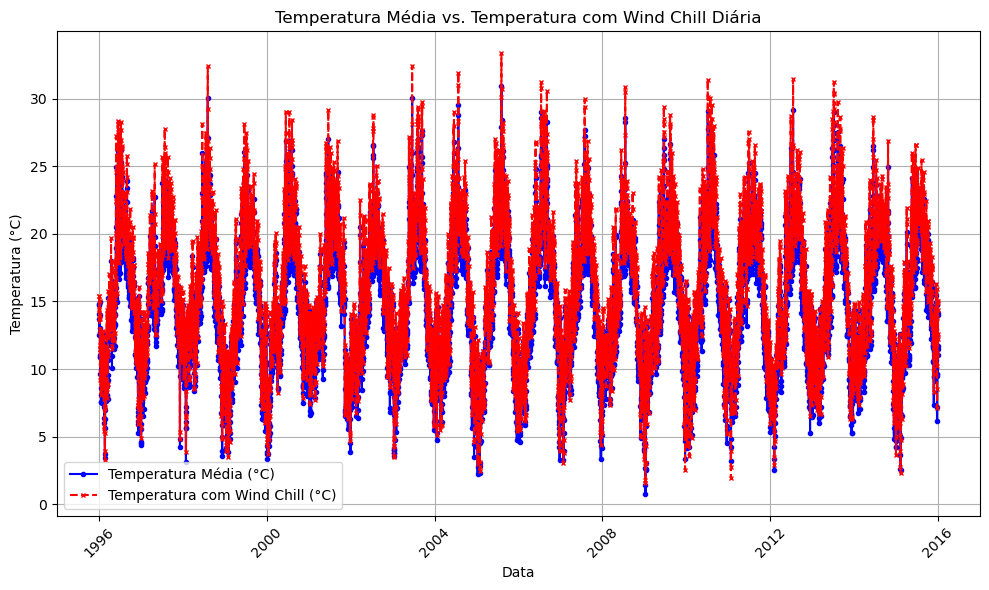

In [33]:
# Carregar o CSV em um DataFrame
df = df_erp 

# Verificar as primeiras linhas para garantir que as colunas 'YY', 'MM', 'DD' existam
print(df.head())

# Garantir que as colunas 'YY', 'MM', 'DD' são inteiros
df[['YY', 'MM', 'DD']] = df[['YY', 'MM', 'DD']].astype(int)

# Criar uma coluna 'date' com o formato 'YYYY-MM-DD'
df['date'] = df['YY'].astype(str) + '-' + df['MM'].astype(str).str.zfill(2) + '-' + df['DD'].astype(str).str.zfill(2)

# Converter a coluna 'date' para datetime
df['date'] = pd.to_datetime(df['date'])

# Verificar o DataFrame após a criação da coluna 'date'
print(df.head())


# Plotar o gráfico
plt.figure(figsize=(10, 6))
plt.plot(df['date'], df['tas'], label='Temperatura Média (°C)', color='blue', marker='o', markersize=3)
plt.plot(df['date'], df['wind_chill'], label='Temperatura com Wind Chill (°C)', color='red', linestyle='--', marker='x', markersize=3)

# Adicionar título e rótulos aos eixos
plt.title(f'Temperatura Média vs. Temperatura com Wind Chill Diária')
plt.xlabel('Data')
plt.ylabel('Temperatura (°C)')
plt.legend()

# Exibir o gráfico
plt.grid(True)
plt.xticks(rotation=45)  # Girar as datas no eixo X para facilitar a leitura
plt.tight_layout()  # Ajusta o layout para não cortar os rótulos
plt.show()


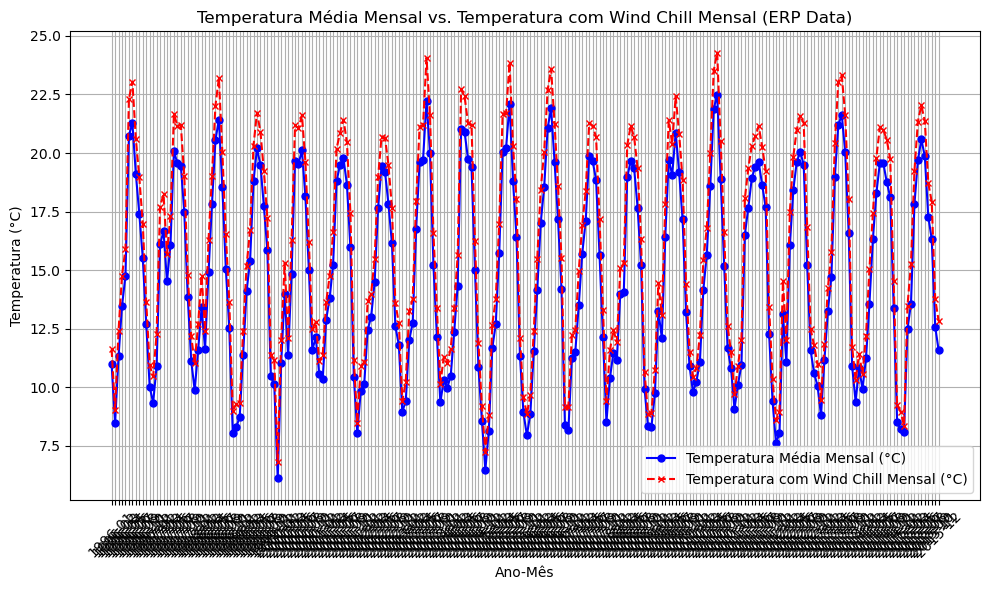

In [34]:
# Carregar os três arquivos CSV
df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_converted_with_wind_chill.csv')
df_epp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_converted_with_wind_chill.csv')
df_etp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_converted_with_wind_chill.csv')

# Função para criar a coluna de data para qualquer DataFrame
def create_date_column(df):
    # Garantir que as colunas 'YY', 'MM', 'DD' são inteiros
    df[['YY', 'MM', 'DD']] = df[['YY', 'MM', 'DD']].astype(int)
    
    # Criar uma coluna 'date' com o formato 'YYYY-MM-DD'
    df['date'] = df['YY'].astype(str) + '-' + df['MM'].astype(str).str.zfill(2) + '-' + df['DD'].astype(str).str.zfill(2)
    
    # Converter a coluna 'date' para datetime
    df['date'] = pd.to_datetime(df['date'])
    
    return df

# Criar a coluna 'date' para todos os DataFrames
df_erp = create_date_column(df_erp)
df_epp = create_date_column(df_epp)
df_etp = create_date_column(df_etp)

# Calcular a média mensal da temperatura
# Vamos agrupar por ano e mês, e depois calcular a média de 'tas' e 'wind_chill'
df_erp['year_month'] = df_erp['date'].dt.to_period('M')  # Agrupar por ano e mês

# Calcular a média mensal para as colunas 'tas' (temperatura média) e 'wind_chill'
df_monthly = df_erp.groupby('year_month')[['tas', 'wind_chill']].mean()

# Plotar o gráfico para a temperatura média mensal e Wind Chill
plt.figure(figsize=(10, 6))
plt.plot(df_monthly.index.astype(str), df_monthly['tas'], label='Temperatura Média Mensal (°C)', color='blue', marker='o', markersize=5)
plt.plot(df_monthly.index.astype(str), df_monthly['wind_chill'], label='Temperatura com Wind Chill Mensal (°C)', color='red', linestyle='--', marker='x', markersize=5)

# Adicionar título e rótulos aos eixos
plt.title(f'Temperatura Média Mensal vs. Temperatura com Wind Chill Mensal (ERP Data)')
plt.xlabel('Ano-Mês')
plt.ylabel('Temperatura (°C)')
plt.legend()

# Exibir o gráfico
plt.grid(True)
plt.xticks(rotation=45)  # Girar as datas no eixo X para facilitar a leitura
plt.tight_layout()  # Ajusta o layout para não cortar os rótulos
plt.show()

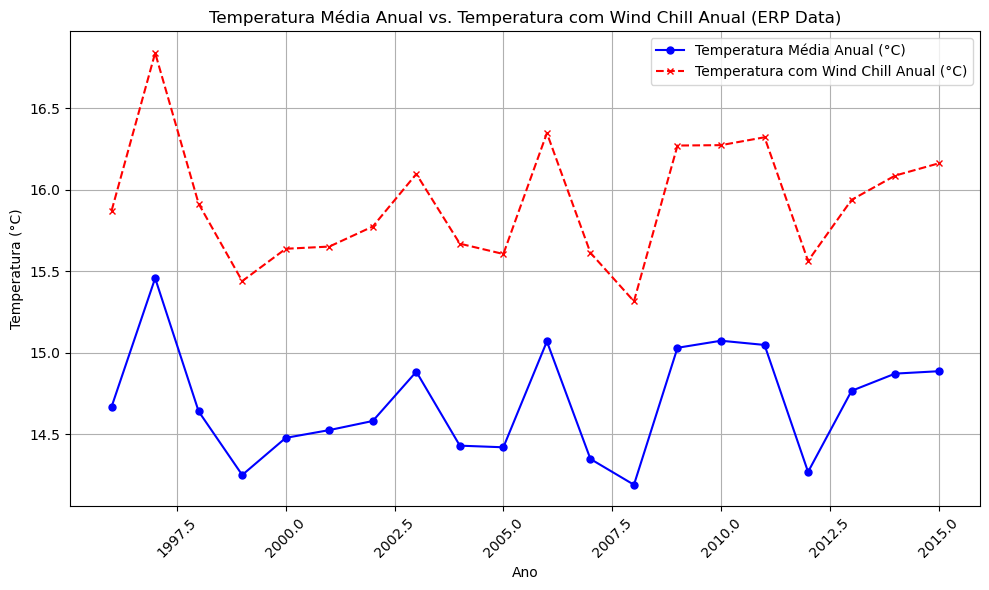

In [35]:
# Carregar os três arquivos CSV
df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_converted_with_wind_chill.csv')
df_epp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_converted_with_wind_chill.csv')
df_etp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_converted_with_wind_chill.csv')
# Função para criar a coluna de data para qualquer DataFrame
def create_date_column(df):
    # Garantir que as colunas 'YY', 'MM', 'DD' são inteiros
    df[['YY', 'MM', 'DD']] = df[['YY', 'MM', 'DD']].astype(int)
    
    # Criar uma coluna 'date' com o formato 'YYYY-MM-DD'
    df['date'] = df['YY'].astype(str) + '-' + df['MM'].astype(str).str.zfill(2) + '-' + df['DD'].astype(str).str.zfill(2)
    
    # Converter a coluna 'date' para datetime
    df['date'] = pd.to_datetime(df['date'])
    
    return df

# Criar a coluna 'date' para todos os DataFrames
df_erp = create_date_column(df_erp)
df_epp = create_date_column(df_epp)
df_etp = create_date_column(df_etp)

# Calcular a média anual da temperatura
# Vamos agrupar por ano, e depois calcular a média de 'tas' e 'wind_chill'
df_erp['year'] = df_erp['date'].dt.year  # Extrair o ano da coluna 'date'

# Calcular a média anual para as colunas 'tas' (temperatura média) e 'wind_chill'
df_annual = df_erp.groupby('year')[['tas', 'wind_chill']].mean()

# Plotar o gráfico para a temperatura média anual e Wind Chill
plt.figure(figsize=(10, 6))
plt.plot(df_annual.index, df_annual['tas'], label='Temperatura Média Anual (°C)', color='blue', marker='o', markersize=5)
plt.plot(df_annual.index, df_annual['wind_chill'], label='Temperatura com Wind Chill Anual (°C)', color='red', linestyle='--', marker='x', markersize=5)

# Adicionar título e rótulos aos eixos
plt.title(f'Temperatura Média Anual vs. Temperatura com Wind Chill Anual (ERP Data)')
plt.xlabel('Ano')
plt.ylabel('Temperatura (°C)')
plt.legend()

# Exibir o gráfico
plt.grid(True)
plt.xticks(rotation=45)  # Girar os anos no eixo X para facilitar a leitura
plt.tight_layout()  # Ajusta o layout para não cortar os rótulos
plt.show()

HEAT WAVE INDEX-  heat wave occurs when "the maximum daily temperature
is at least 5°C higher than the average value for that period, for at least six consecutive days."
This definition is not related to health impacts, as it focuses solely on climate variability. Clearly,
three days with temperatures 10°C above average would have a greater impact on health than seven
days with temperatures only 5°C above average [2

In [36]:
def analyze_heat_wave (csv_file):
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    degrees_above_threshold = 0
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['tasmax'] >= row['tas'] + 5:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            degrees_above_threshold += row['tasmax'] - (row['tas'] + 5)
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                heat_wave_end = row['date'] - pd.Timedelta(days=1)  # The previous day is the end
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "degrees_above_threshold": degrees_above_threshold
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            degrees_above_threshold = 0
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        heat_wave_end = row['date']
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "degrees_above_threshold": degrees_above_threshold
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [38]:
# Carregar os arquivos CSV convertidos em DataFrames
df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_converted_with_wind_chill.csv')
df_epp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_converted_with_wind_chill.csv')
df_etp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_converted_with_wind_chill.csv')

# Exibir as primeiras linhas de cada DataFrame
print(df_erp.head())
print(df_epp.head())
print(df_etp.head())

analyze_heat_wave (df_etp)

       YY   MM   DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  14.111902  15.887201  10.946985  86.755997  5.176228   
1  1996.0  1.0  2.0  12.541010  15.109399   8.969110  91.813049  2.046499   
2  1996.0  1.0  3.0  14.728113  16.028497  12.791559  97.225250  3.764771   
3  1996.0  1.0  4.0  14.850671  15.920404  13.415521  94.710892  4.311609   
4  1996.0  1.0  5.0  13.673181  15.552148  12.153009  93.431549  3.309732   

     heat_index  wind_chill  
0  1.824421e+27   14.378360  
1  1.661882e+27   13.740071  
2  4.610301e+27   15.436498  
3  4.027201e+27   15.424079  
4  2.601091e+27   14.413770  
       YY   MM   DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996.0  1.0  1.0  11.673853  13.337671   9.096735  97.802551  3.527462   
1  1996.0  1.0  2.0   9.494196  11.780542   7.350732  85.961823  2.174941   
2  1996.0  1.0  3.0  12.219019  14.014917  10.674646  95.754532  7.470380   
3  1996.0  1.0  4.0  14.409387  15.263116  12.215

{'total_heat_waves': 158,
 'heat_waves': [{'start_date': Timestamp('1996-04-08 00:00:00'),
   'end_date': Timestamp('1996-04-15 00:00:00'),
   'duration': 8,
   'degrees_above_threshold': 9.410186767578075},
  {'start_date': Timestamp('1996-05-22 00:00:00'),
   'end_date': Timestamp('1996-05-30 00:00:00'),
   'duration': 9,
   'degrees_above_threshold': 18.960754394531254},
  {'start_date': Timestamp('1996-06-09 00:00:00'),
   'end_date': Timestamp('1996-06-18 00:00:00'),
   'duration': 10,
   'degrees_above_threshold': 19.797851562499936},
  {'start_date': Timestamp('1996-06-22 00:00:00'),
   'end_date': Timestamp('1996-07-01 00:00:00'),
   'duration': 10,
   'degrees_above_threshold': 17.565032958984478},
  {'start_date': Timestamp('1996-07-08 00:00:00'),
   'end_date': Timestamp('1996-07-24 00:00:00'),
   'duration': 17,
   'degrees_above_threshold': 52.929260253906385},
  {'start_date': Timestamp('1996-07-27 00:00:00'),
   'end_date': Timestamp('1996-08-02 00:00:00'),
   'duration'